# PISA Example of a generic diffuse analysis

## Setup

Usually you would need to export the location of the data, and the config files to `PISA_RESOURCES`.

In [1]:
import numpy as np
from uncertainties import unumpy as unp
import matplotlib.pyplot as plt
import copy
import os
import pisa
from pisa.core.distribution_maker import DistributionMaker
from pisa.core.pipeline import Pipeline
from pisa.analysis.analysis import Analysis
from pisa import FTYPE, ureg

<< PISA is running in double precision (FP64) mode; numba is running on CPU (single core) >>


In [2]:
fridge_path = '/home/jp/pone/pisa_tutorial/pone_fridge'

In [3]:
os.environ['PISA_RESOURCES'] = fridge_path

In [4]:
myfiles_path = '/home/jp/pone/pisa_tutorial/pone_fridge/diffuse_generic'

## Model

We can now instantiate the `model` (given our configs) that we later fit to data. This can contain multipe `Pipelines` in a `DistributionMaker`, one for each type of event, such as neutrinos, muons, pure noise, etc.

In [5]:
model = DistributionMaker([
    os.path.join(myfiles_path,"pipeline/neutrino_pipeline.cfg"),
])

[ WARNING] /home/jp/anaconda3/envs/pisa/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")

Calibration file None


In [6]:
# Confirming that the data has been loaded
loader = model.pipelines[0]
loader

stage number,name,calc_mode,apply_mode,has setup,has compute,has apply,# fixed params,# free params
0,csv_loader,events,events,True,False,True,0,0
1,daemon_flux,events,events,True,True,False,26,0
2,astrophysical,events,events,True,True,True,0,2
3,two_nu_osc,events,events,False,False,True,2,0
4,aeff,,events,False,False,True,4,1
5,hist,events,"""reco_binning"": 10 (reco_energy) x 10 (reco_coszen)",True,False,True,0,0


Our model has a number of free parameters, that will be used in our fit to the data

In [7]:
model.params

name,value,nominal_value,range,prior,units,is_fixed
daemon_K_158G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_K_2P,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_K_31G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_antiK_158G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_antiK_2P,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_antiK_31G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_n_158G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_n_2P,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_p_158G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True
daemon_p_2P,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,True


In [8]:
model.run()

[ WARNING] /home/jp/software/pisa/pisa/stages/flux/daemon_flux.py:174: NumbaWarning: 
Compilation is falling back to object mode WITHOUT looplifting enabled because Function "make_2d_flux_map" failed type inference due to: non-precise type pyobject
During: typing of argument at /home/jp/software/pisa/pisa/stages/flux/daemon_flux.py (189)

File "../pisa/stages/flux/daemon_flux.py", line 189:
def make_2d_flux_map(flux_obj,
    <source elided>

    for index in range(len(icangles)):
    ^

  @jit(forceobj=True)



## Retrieve Outputs

Looking at the contents of the pipeline

In [9]:
maps = model.pipelines[0].get_outputs()

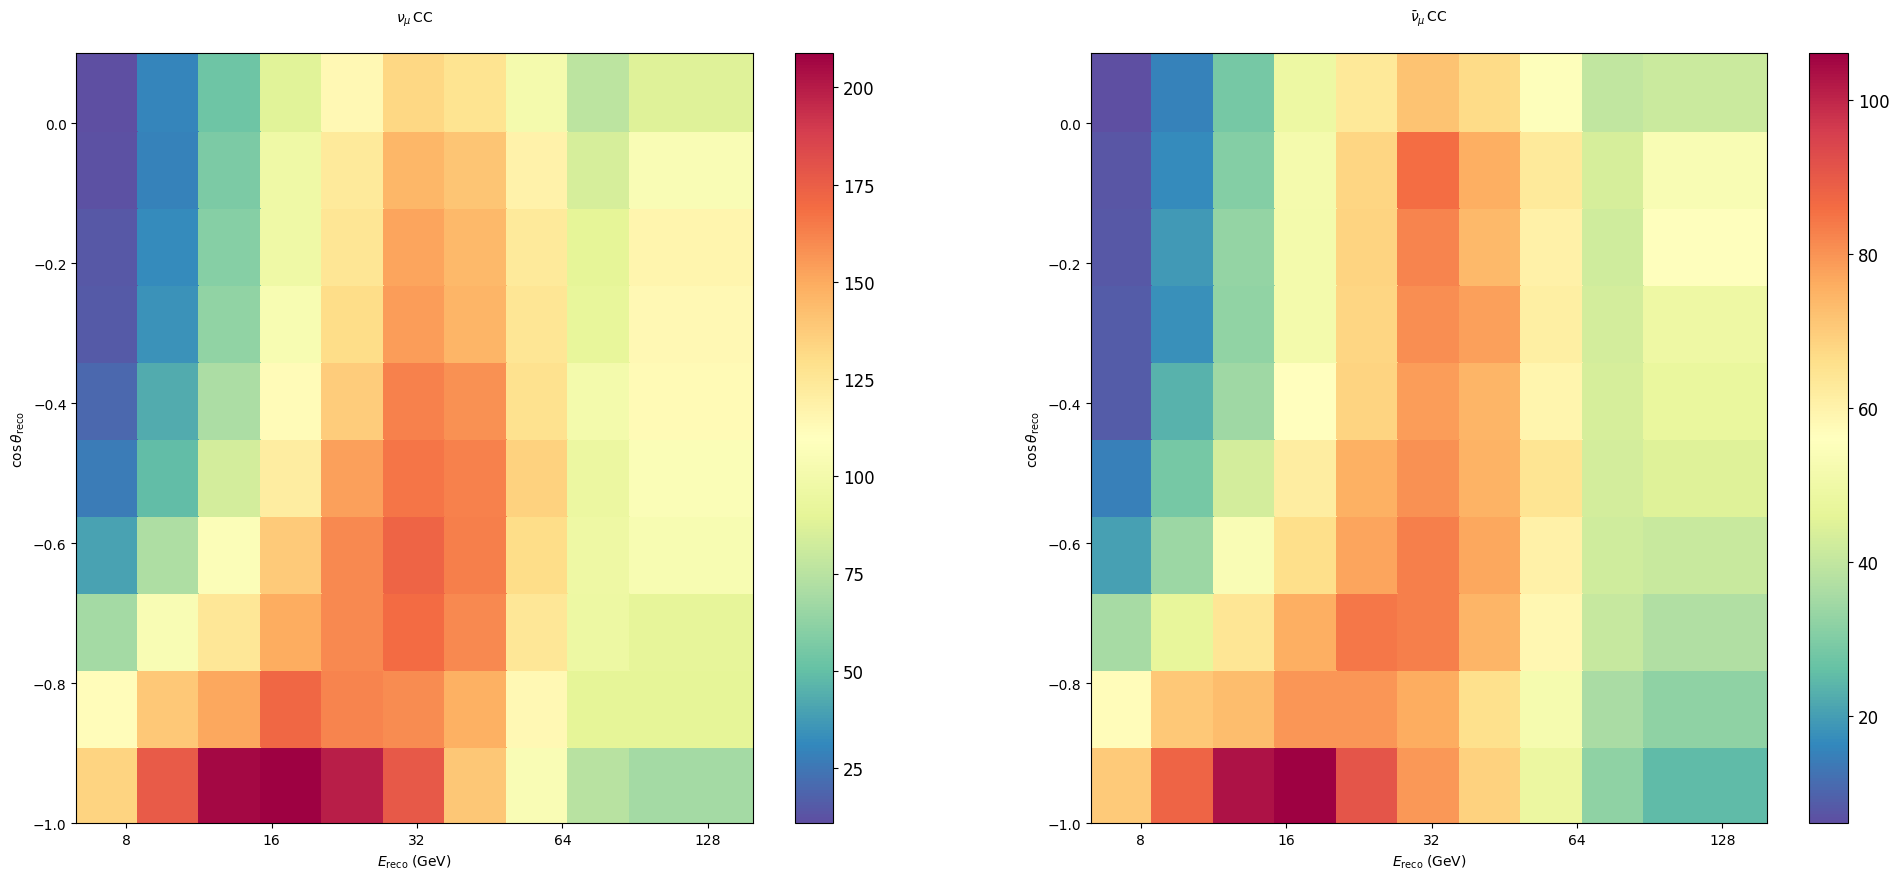

In [10]:
fig, axes = plt.subplots(1,2, figsize=(24,10))
plt.subplots_adjust(hspace=0.5)
axes = axes.flatten()

for m, ax in zip(maps, axes):
    m.plot(ax=ax, full_ax=ax)

If we are interested in just the total expecatation from the full model (all neutrinos + muons), we can do the following:

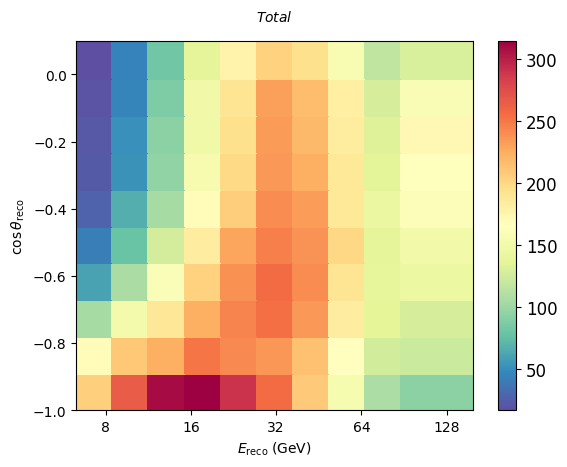

In [11]:
# Looking at the total distribution of events
model.get_outputs(return_sum=True).plot()

## Diff plots

Let's explore how a change in one of our parameters affects the observed events

In [12]:
# reset all free parameters to put them back to nominal values
model.reset_free()
model.params.astro_norm = 0.
model.params.astro_delta=0.
#astro.compute_function()

nominal = model.get_outputs(return_sum=True)

# shift one parameter
model.params.astro_norm = 1e10 # This is a scale with respect to the flux in the stage
model.params.astro_delta= 1.


model.run()
sys = model.get_outputs(return_sum=True)

(<Figure size 640x480 with 2 Axes>,
 <Axes: title={'center': '$Total$'}, xlabel='$E_{\\rm reco} \\; \\left( \\mathrm{GeV} \\right)$', ylabel='$\\cos{\\theta}_{\\rm reco}$'>,
 <matplotlib.colorbar.Colorbar at 0x7f124bf4b3d0>)

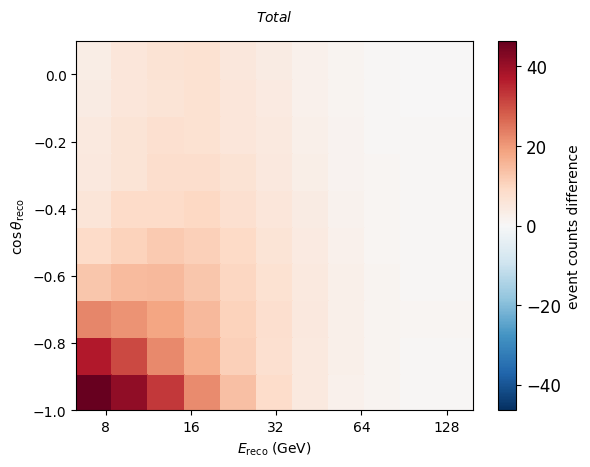

In [14]:
((sys[0]-nominal[0])).plot(symm=True, clabel="event counts difference")

## Get Data

Loading a distribution as pseudo-data

In [15]:
model.reset_free()
model.params.astro_norm = 1.E10
model.params.astro_delta=1
#astro.compute_function()

pseudo_data = model.get_outputs(return_sum=True)

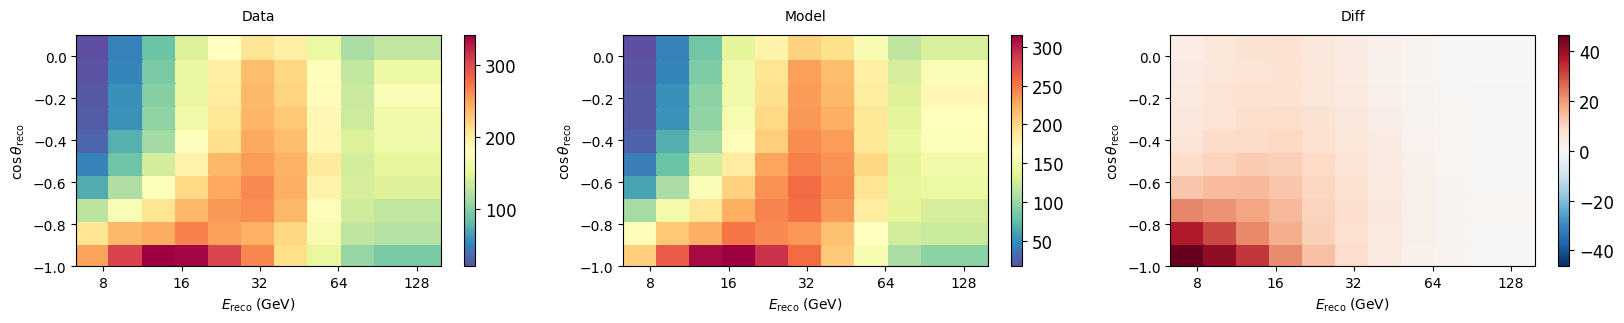

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(20, 3))

model.reset_free()
model.params.astro_norm = 0.
model.params.astro_delta=0.
nominal = model.get_outputs(return_sum=True)

pseudo_data.plot(ax=ax[0], title="Data", full_ax=ax[0])
nominal.plot(ax=ax[1], title="Model", full_ax=ax[1])
(pseudo_data - nominal).plot(ax=ax[2], symm=True, title="Diff", full_ax=ax[2])

## Fitting

For fitting we need to configure a minimizer, several standard cfgs are available, but you can also define your own.
For the fit we need to choose a `metric`, and by default, theta23 octants, which are quasi degenerate, are fit seperately, which means two fits are run.

In [17]:
local_fit_minuit = {
    "method": "iminuit",
    "method_kwargs": {
        "errors": 0.1,
        "precision": 1e-14,  # default: double precision
        "tol": 1e-2,  # default: 0.1
        "run_simplex": False,
        "run_migrad": True
    },
    "local_fit_kwargs": None
}

In [18]:
fit_octant = {
    "method": "octants",
    "method_kwargs": {
        "angle": "theta23",
        "inflection_point": 45 * ureg.degrees,
    },
    "local_fit_kwargs": local_fit_minuit
}

In [19]:
ana = Analysis()
ana.pprint=True

In [20]:
result = ana.fit_recursively(
    data_dist=pseudo_data,
    hypo_maker=model,
    metric='chi2',
    external_priors_penalty=None,
    **local_fit_minuit
)

                                                                       
 iter   funcalls      chi2     | astro_delta   astro_norm   aeff_scale 
------ ---------- ------------ + ------------ ------------ ------------
  0        0       6.40729e+04 |  0.00000e+00  9.53674e+07  9.30000e-01
  0        1       2.35969e+04 |  9.11452e-02  9.53674e+07  9.30000e-01
  0        2       1.63835e+05 | -9.11452e-02  9.53674e+07  9.30000e-01
  0        3       5.81725e+04 |  9.11765e-03  9.53674e+07  9.30000e-01
  0        4       7.05306e+04 | -9.11765e-03  9.53674e+07  9.30000e-01
  0        5       6.34586e+04 |  9.11768e-04  9.53674e+07  9.30000e-01
  0        6       6.46928e+04 | -9.11768e-04  9.53674e+07  9.30000e-01
  0        7       1.08384e+08 |  0.00000e+00  1.39670e+11  9.30000e-01
  0        8       9.73564e+07 |  0.00000e+00  1.25462e+11  9.30000e-01
  0        9       1.63800e+06 |  0.00000e+00  2.13167e+09  9.30000e-01
  0        10      5.35939e+05 |  0.00000e+00  7.09629e+08  9.30